In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score # métrica de evaluación
from sklearn.metrics import classification_report
from sklearn import metrics

# Análisis Exploratorio

In [2]:
df_nasa = pd.read_csv('https://raw.githubusercontent.com/pokengineer/DataScience/main/datasets/asteroids_nasa.csv')
df_nasa.head(5)

,Neo Reference ID,Name,Absolute Magnitude,Est Dia in KM(min),Est Dia in KM(max),Est Dia in M(min),Est Dia in M(max),Est Dia in Miles(min),Est Dia in Miles(max),Est Dia in Feet(min),...,Asc Node Longitude,Orbital Period,Perihelion Distance,Perihelion Arg,Aphelion Dist,Perihelion Time,Mean Anomaly,Mean Motion,Equinox,Hazardous
0,3703080,3703080,21.6,0.127220,0.284472,127.219879,284.472297,0.079051,0.176763,417.388066,...,314.373913,609.599786,0.808259,57.257470,2.005764,2.458162e+06,264.837533,0.590551,J2000,True
1,3723955,3723955,21.3,0.146068,0.326618,146.067964,326.617897,0.090762,0.202951,479.225620,...,136.717242,425.869294,0.718200,313.091975,1.497352,2.457795e+06,173.741112,0.845330,J2000,False
2,2446862,2446862,20.3,0.231502,0.517654,231.502122,517.654482,0.143849,0.321655,759.521423,...,259.475979,643.580228,0.950791,248.415038,1.966857,2.458120e+06,292.893654,0.559371,J2000,True
3,3092506,3092506,27.4,0.008801,0.019681,8.801465,19.680675,0.005469,0.012229,28.876199,...,57.173266,514.082140,0.983902,18.707701,1.527904,2.457902e+06,68.741007,0.700277,J2000,False
4,3514799,3514799,21.6,0.127220,0.284472,127.219879,284.472297,0.079051,0.176763,417.388066,...,84.629307,495.597821,0.967687,158.263596,1.483543,2.457814e+06,135.142133,0.726395,J2000,True


In [3]:
# verificamos los tipos de datos
df_nasa.dtypes

,0
Neo Reference ID,int64
Name,int64
Absolute Magnitude,float64
Est Dia in KM(min),float64
Est Dia in KM(max),float64
Est Dia in M(min),float64
Est Dia in M(max),float64
Est Dia in Miles(min),float64
Est Dia in Miles(max),float64
Est Dia in Feet(min),float64


In [4]:
print("Tamaño del dataframe : {}".format(df_nasa.shape))

Tamaño del dataframe : (4687, 40)


In [5]:
# Verificamos si hay valores nulos para imputar
df_nasa.isnull().sum()

,0
Neo Reference ID,0
Name,0
Absolute Magnitude,0
Est Dia in KM(min),0
Est Dia in KM(max),0
Est Dia in M(min),0
Est Dia in M(max),0
Est Dia in Miles(min),0
Est Dia in Miles(max),0
Est Dia in Feet(min),0


Hazardous
False    3932
True      755
Name: count, dtype: int64


<Axes: xlabel='Hazardous', ylabel='count'>

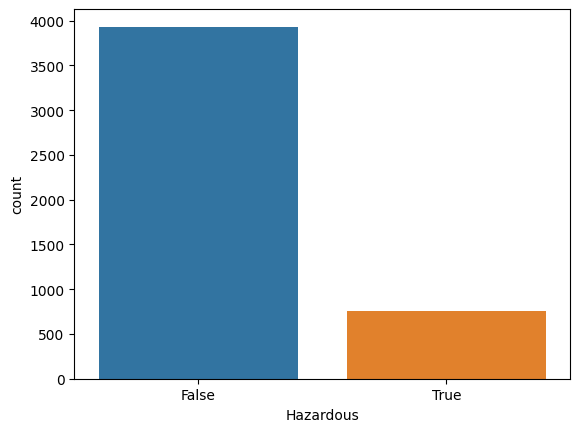

In [6]:
# Analisis de la distribución de la variable target "Hazardous"
print( df_nasa.Hazardous.value_counts() )
sns.countplot(x='Hazardous', data=df_nasa, hue='Hazardous', legend=False)

# Correlación de Variables

<Axes: >

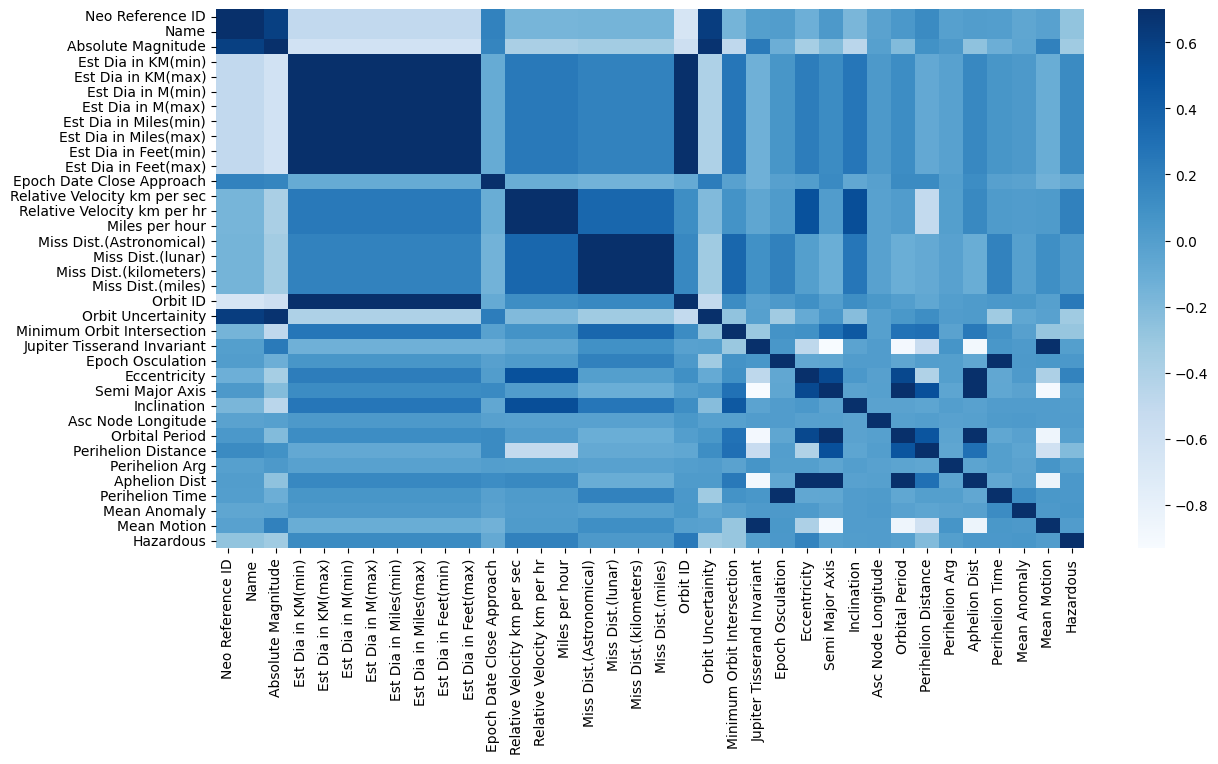

In [7]:
plt.figure(figsize=(14,7))
sns.heatmap(df_nasa.drop(['Close Approach Date','Orbiting Body','Orbit Determination Date','Equinox'],axis=1).corr(), vmax=.7, cmap ='Blues', fmt=".2f")

In [8]:
df_nasa_corr = df_nasa.drop(['Close Approach Date','Orbiting Body','Orbit Determination Date','Equinox'],axis=1).corr()[["Hazardous"]]*100 # lo pasamos a porcentajes
df_nasa_corr = df_nasa_corr.drop("Hazardous", axis=0) # eliminamos la variable target
df_nasa_corr = abs(df_nasa_corr) # nos interesa el valor absouluto
df_nasa_corr = df_nasa_corr.sort_values(["Hazardous"], ascending=False) # ordenamos en forma descendente
df_nasa_corr

,Hazardous
Orbit Uncertainity,32.872134
Absolute Magnitude,32.552193
Minimum Orbit Intersection,28.894902
Name,26.902814
Neo Reference ID,26.902814
Orbit ID,24.736904
Perihelion Distance,20.702693
Relative Velocity km per sec,19.197018
Miles per hour,19.197018
Relative Velocity km per hr,19.197018


# Seleccionamos las variables que vamos a utilizar y hacemos el Split

In [9]:
# dropeo ['Orbiting Body','Equinox'] porque en todos los casos es earth y J2000
df_nasa.drop(['Orbiting Body','Equinox'],axis=1, inplace=True)

In [10]:
df_nasa.columns

Index(['Neo Reference ID', 'Name', 'Absolute Magnitude', 'Est Dia in KM(min)',
       'Est Dia in KM(max)', 'Est Dia in M(min)', 'Est Dia in M(max)',
       'Est Dia in Miles(min)', 'Est Dia in Miles(max)',
       'Est Dia in Feet(min)', 'Est Dia in Feet(max)', 'Close Approach Date',
       'Epoch Date Close Approach', 'Relative Velocity km per sec',
       'Relative Velocity km per hr', 'Miles per hour',
       'Miss Dist.(Astronomical)', 'Miss Dist.(lunar)',
       'Miss Dist.(kilometers)', 'Miss Dist.(miles)', 'Orbit ID',
       'Orbit Determination Date', 'Orbit Uncertainity',
       'Minimum Orbit Intersection', 'Jupiter Tisserand Invariant',
       'Epoch Osculation', 'Eccentricity', 'Semi Major Axis', 'Inclination',
       'Asc Node Longitude', 'Orbital Period', 'Perihelion Distance',
       'Perihelion Arg', 'Aphelion Dist', 'Perihelion Time', 'Mean Anomaly',
       'Mean Motion', 'Hazardous'],
      dtype='object')

In [ ]:
df = df_nasa.drop(['Close Approach Date','Orbit Determination Date'],axis=1)
X_nasa = df.drop("Hazardous",axis=1)
y_nasa = df["Hazardous"]
X_nasa.head()

,Neo Reference ID,Name,Absolute Magnitude,Est Dia in KM(min),Est Dia in KM(max),Est Dia in M(min),Est Dia in M(max),Est Dia in Miles(min),Est Dia in Miles(max),Est Dia in Feet(min),...,Semi Major Axis,Inclination,Asc Node Longitude,Orbital Period,Perihelion Distance,Perihelion Arg,Aphelion Dist,Perihelion Time,Mean Anomaly,Mean Motion
0,3703080,3703080,21.6,0.127220,0.284472,127.219879,284.472297,0.079051,0.176763,417.388066,...,1.407011,6.025981,314.373913,609.599786,0.808259,57.257470,2.005764,2.458162e+06,264.837533,0.590551
1,3723955,3723955,21.3,0.146068,0.326618,146.067964,326.617897,0.090762,0.202951,479.225620,...,1.107776,28.412996,136.717242,425.869294,0.718200,313.091975,1.497352,2.457795e+06,173.741112,0.845330
2,2446862,2446862,20.3,0.231502,0.517654,231.502122,517.654482,0.143849,0.321655,759.521423,...,1.458824,4.237961,259.475979,643.580228,0.950791,248.415038,1.966857,2.458120e+06,292.893654,0.559371
3,3092506,3092506,27.4,0.008801,0.019681,8.801465,19.680675,0.005469,0.012229,28.876199,...,1.255903,7.905894,57.173266,514.082140,0.983902,18.707701,1.527904,2.457902e+06,68.741007,0.700277
4,3514799,3514799,21.6,0.127220,0.284472,127.219879,284.472297,0.079051,0.176763,417.388066,...,1.225615,16.793382,84.629307,495.597821,0.967687,158.263596,1.483543,2.457814e+06,135.142133,0.726395


In [12]:
# Hacemos el Split 70-30 para train-test
X_train, X_test, y_train, y_test = train_test_split(X_nasa, y_nasa, test_size=0.3, stratify = y_nasa, random_state=0)

In [13]:
# Creamos y entrenamos modelo
treeclf = DecisionTreeClassifier(max_depth=3, random_state=1) # maxima profundidad = 3
treeclf.fit(X_train, y_train) # entrenamos el árbol

DecisionTreeClassifier(max_depth=3, random_state=1)

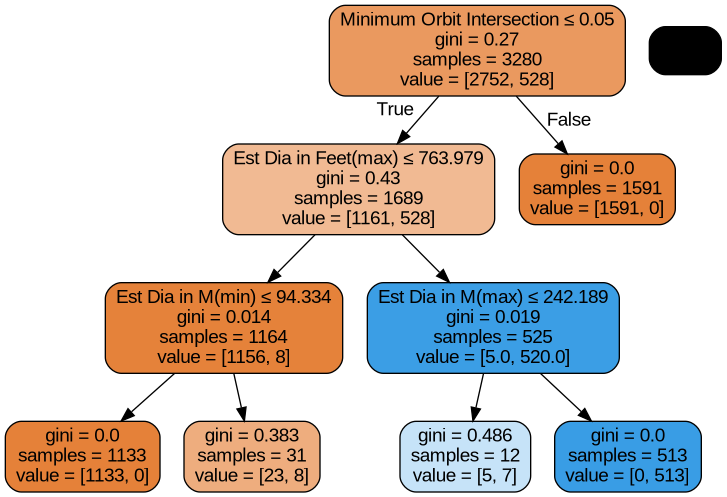

In [14]:
# Importamos la librería que necesitamos
from sklearn.tree import export_graphviz
from IPython.display import Image
import pydotplus

# Visualizamos el árbol generado usando graphviz
dot_data = export_graphviz(treeclf, out_file=None,
                feature_names=X_nasa.columns,
                filled=True, rounded=True,
                special_characters=True)
graph = pydotplus.graph_from_dot_data(dot_data)
Image(graph.create_png())

In [15]:
y_pred_tc = treeclf.predict(X_test)

#Exactitud del modelo
print('Exactitud (accuracy) del modelo: {:.2f} %'.format(accuracy_score(y_test, y_pred_tc)*100))
print("-"*100)

# Reporte del clasificador
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred_tc))

Exactitud (accuracy) del modelo: 99.36 %
----------------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

       False       1.00      1.00      1.00      1180
        True       0.98      0.98      0.98       227

    accuracy                           0.99      1407
   macro avg       0.99      0.99      0.99      1407
weighted avg       0.99      0.99      0.99      1407



# Comparamos con naive bayes

In [17]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.naive_bayes import GaussianNB

bayes_multi = MultinomialNB()
bayes_multi.fit(X_train, y_train)
y_pred_nb = bayes_multi.predict(X_test)
#Exactitud del modelo
print('Exactitud (accuracy) del modelo: {:.2f} %'.format(accuracy_score(y_test, y_pred_nb)*100))
print("-"*100)

# Reporte del clasificador
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred_nb))

Exactitud (accuracy) del modelo: 49.96 %
----------------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

       False       0.85      0.49      0.62      1180
        True       0.17      0.55      0.26       227

    accuracy                           0.50      1407
   macro avg       0.51      0.52      0.44      1407
weighted avg       0.74      0.50      0.56      1407



# Ejercicio
- ¿Cómo se compara el performance del arbol con Naive bayes en este dataset?
- usando treeclf.feature_importances_ podemos ver la importancia de cada una de las columnas de X para el modelo, ¿que sucede con los arboles con menor profundidad?
- implementar un modelo de bosque aleatoreo ([random forest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)) 
- ¿Cual es la diferencia entre los hiperparametros min_samples_split y min_samples_leaf?
- ¿Como se compara la performance de un arbol de profundidad 1, 3 o 10?
- ¿Afectará al modelo si escalamos las variables?

- Comparando la performance del arbol con Naive bayes, observamos que el arbol consigue resultados de precision y recall del 100%. Mientras que naive bayes conseguia porcentajes del 85% em precision y 49% en recall. Analizando la estructura del arbol, podemos inferir que los cortes que escogio el modelo tanto en el primer nivel como en el segundo utilizan las mismas features (Est Dia in Feet(max) y Est Dia in M(max)) solo cambiando la unidad, por lo que sospechamos que el modelo esta overfiteado.

In [19]:
# Importancia de features del árbol entrenado (max_depth=3)
importancias_d3 = pd.Series(treeclf.feature_importances_, index=X_nasa.columns).sort_values(ascending=False)
print("Importancia de features - max_depth=3")
print(importancias_d3[importancias_d3 > 0])

# Entrenamos árboles con menor profundidad para comparar
tree_d1 = DecisionTreeClassifier(max_depth=1, random_state=1).fit(X_train, y_train)
tree_d2 = DecisionTreeClassifier(max_depth=2, random_state=1).fit(X_train, y_train)

importancias_d1 = pd.Series(tree_d1.feature_importances_, index=X_nasa.columns)
importancias_d2 = pd.Series(tree_d2.feature_importances_, index=X_nasa.columns)

# Comparamos las importancias entre las distintas profundidades
comparacion_importancias = pd.DataFrame({
    'max_depth=1': importancias_d1,
    'max_depth=2': importancias_d2,
    'max_depth=3': importancias_d3
}).fillna(0)
comparacion_importancias = comparacion_importancias[(comparacion_importancias.T != 0).any()]
comparacion_importancias

Importancia de features - max_depth=3
Est Dia in Feet(max)          0.806269
Minimum Orbit Intersection    0.184413
Est Dia in M(max)             0.004689
Est Dia in M(min)             0.004629
dtype: float64


,max_depth=1,max_depth=2,max_depth=3
Est Dia in Feet(max),0.0,0.813852,0.806269
Est Dia in M(max),0.0,0.000000,0.004689
Est Dia in M(min),0.0,0.000000,0.004629
Minimum Orbit Intersection,1.0,0.186148,0.184413


- Con `feature_importances_` vemos que en el árbol de profundidad 3 (`treeclf`) solo un puñado de columnas tiene importancia distinta de cero (las que efectivamente se usaron en algún corte del árbol); el resto queda en cero porque nunca se usan para dividir los nodos. A medida que reducimos la profundidad máxima, el número de features con importancia no nula disminuye (con `max_depth=1` solo puede haber una única feature con importancia, la del primer corte de la raíz), y esa importancia se concentra cada vez más en las 1 o 2 variables más discriminantes (`Est Dia in Feet(max)` / `Est Dia in M(max)`, que son la misma medida en distintas unidades). Es decir, árboles menos profundos son más "selectivos": ignoran variables que solo aportarían valor en refinamientos posteriores y toda la importancia se acumula en las features usadas en los primeros splits, que son las que más reducen la impureza.

In [20]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(max_depth=6)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

              precision    recall  f1-score   support

       False       1.00      1.00      1.00      1180
        True       0.99      0.98      0.98       227

    accuracy                           0.99      1407
   macro avg       0.99      0.99      0.99      1407
weighted avg       0.99      0.99      0.99      1407



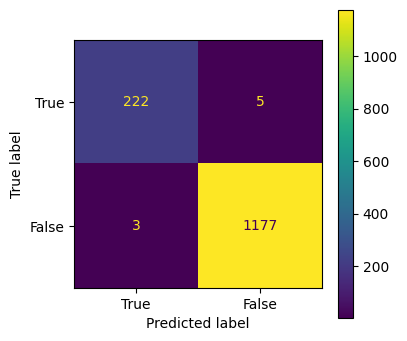

In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
import numpy as np
clf_list = []

cm = confusion_matrix(y_test, y_pred)
cm = np.rot90(cm, 2)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.flip(model.classes_))
fig, ax = plt.subplots(figsize=(4,4))
disp.plot(ax=ax)
print(classification_report(y_test, y_pred))
clf_list.append(model)

- `min_samples_split` es la cantidad mínima de muestras que debe tener un nodo para que el algoritmo *considere* dividirlo; si un nodo tiene menos muestras que ese valor, se convierte directamente en hoja y no se evalúa ningún split. Se aplica sobre el nodo padre, antes de partirlo.
- `min_samples_leaf` es la cantidad mínima de muestras que debe quedar en *cada uno* de los nodos hijos (hojas) resultantes de un split para que ese split sea válido. Se aplica sobre los nodos hijos, después de partirlo: aunque el nodo padre cumpla `min_samples_split`, el corte se descarta si alguna de las dos hojas resultantes quedaría con menos muestras que `min_samples_leaf`.
- En la práctica, `min_samples_leaf` es una restricción más fuerte contra el overfitting porque evita splits muy desbalanceados (por ejemplo, dividir un nodo de 100 muestras en 99 y 1), mientras que `min_samples_split` solo controla si vale la pena intentar dividir el nodo, sin garantizar nada sobre el tamaño de las hojas que resulten.

In [27]:
tree_d1 = DecisionTreeClassifier(max_depth=1, random_state=1).fit(X_train, y_train)
tree_d3 = DecisionTreeClassifier(max_depth=3, random_state=1).fit(X_train, y_train)
tree_d10 = DecisionTreeClassifier(max_depth=10, random_state=1).fit(X_train, y_train)

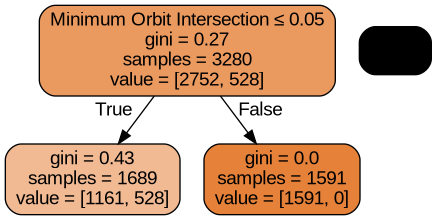

In [28]:
dot_data = export_graphviz(tree_d1, out_file=None,
                feature_names=X_nasa.columns,
                filled=True, rounded=True,
                special_characters=True)
graph = pydotplus.graph_from_dot_data(dot_data)
Image(graph.create_png())

In [29]:
y_pred_tc = tree_d1.predict(X_test)

#Exactitud del modelo
print('Exactitud (accuracy) del modelo: {:.2f} %'.format(accuracy_score(y_test, y_pred_tc)*100))
print("-"*100)

# Reporte del clasificador
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred_tc))

Exactitud (accuracy) del modelo: 83.87 %
----------------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

       False       0.84      1.00      0.91      1180
        True       0.00      0.00      0.00       227

    accuracy                           0.84      1407
   macro avg       0.42      0.50      0.46      1407
weighted avg       0.70      0.84      0.77      1407



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


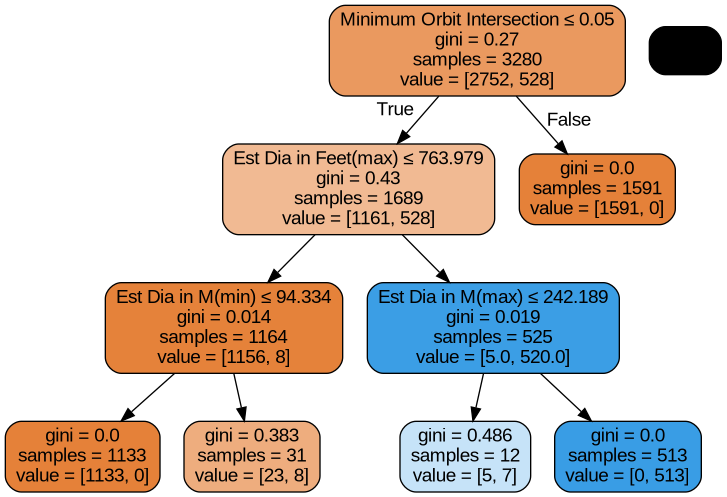

In [30]:
dot_data = export_graphviz(tree_d3, out_file=None,
                feature_names=X_nasa.columns,
                filled=True, rounded=True,
                special_characters=True)
graph = pydotplus.graph_from_dot_data(dot_data)
Image(graph.create_png())

In [31]:
y_pred_tc = tree_d3.predict(X_test)

#Exactitud del modelo
print('Exactitud (accuracy) del modelo: {:.2f} %'.format(accuracy_score(y_test, y_pred_tc)*100))
print("-"*100)

# Reporte del clasificador
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred_tc))

Exactitud (accuracy) del modelo: 99.36 %
----------------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

       False       1.00      1.00      1.00      1180
        True       0.98      0.98      0.98       227

    accuracy                           0.99      1407
   macro avg       0.99      0.99      0.99      1407
weighted avg       0.99      0.99      0.99      1407



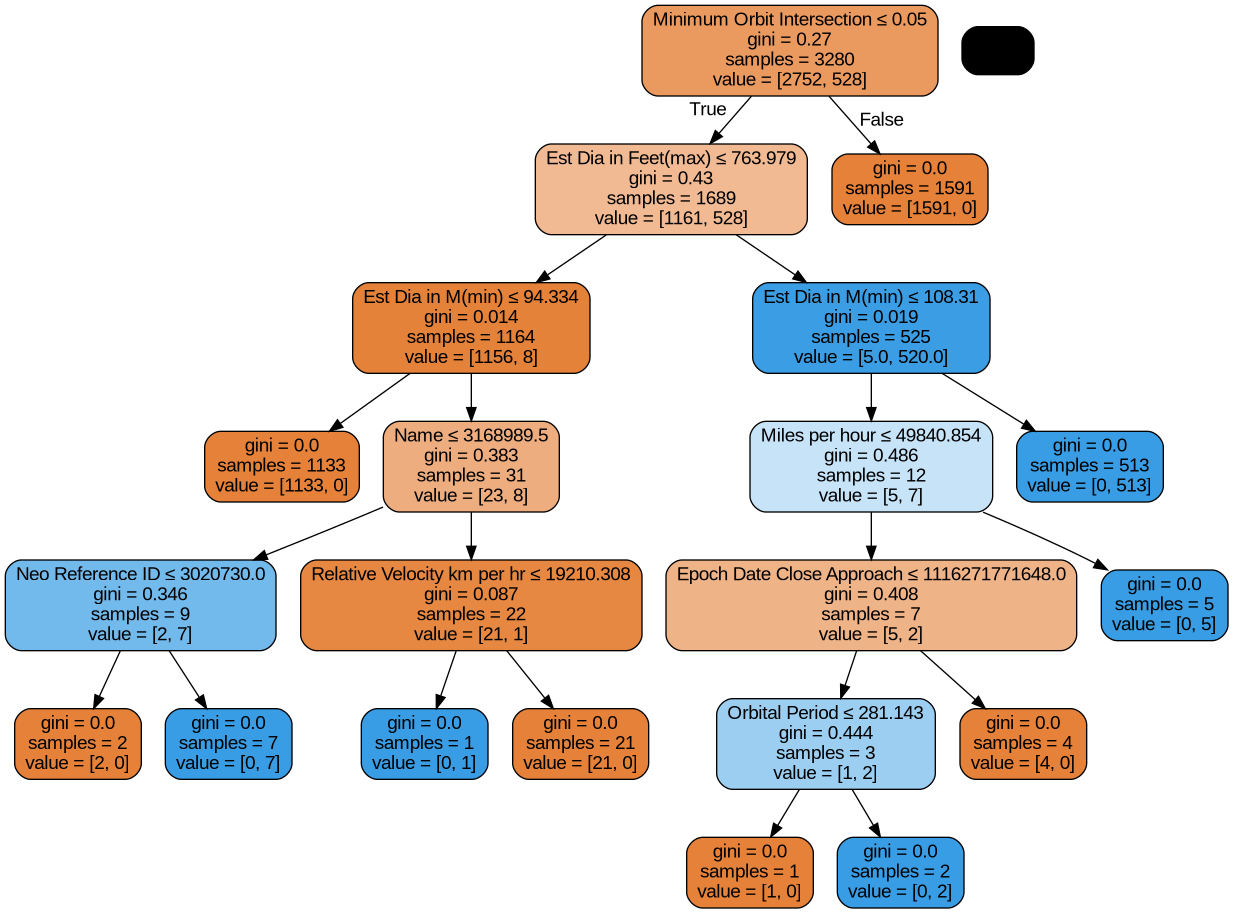

In [32]:
dot_data = export_graphviz(tree_d10, out_file=None,
                feature_names=X_nasa.columns,
                filled=True, rounded=True,
                special_characters=True)
graph = pydotplus.graph_from_dot_data(dot_data)
Image(graph.create_png())

In [35]:
y_pred_tc = tree_d10.predict(X_test)

#Exactitud del modelo
print('Exactitud (accuracy) del modelo: {:.2f} %'.format(accuracy_score(y_test, y_pred_tc)*100))
print("-"*100)

# Reporte del clasificador
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred_tc))

Exactitud (accuracy) del modelo: 99.43 %
----------------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

       False       1.00      1.00      1.00      1180
        True       0.98      0.98      0.98       227

    accuracy                           0.99      1407
   macro avg       0.99      0.99      0.99      1407
weighted avg       0.99      0.99      0.99      1407



- Podemos observar con 1 nivel obtenemos una performance de 84% en precision de False y 0% en True, lo cual es muy bajo comparado a los otros 2 arboles. Como habiamos mencionado anteriormente, con 3 niveles de profundidad, el modelo ya nos daba una buena performace que nos hacia sospechar que overfiteaba, comparondolo con 10 niveles, los resultados no mejoraron (Porque eran imposibles de mejorar) y obtenemos algo que seguramente este overfiteado.

- El modelo no se veria afectado si escalasemos las variables dado que los arboles de decision buscan, para cada feature, un umbral que separe mejor las clases (segun la impureza, Gini en este caso), evaluando cada columna de forma independiente. Escalar (por ejemplo con StandardScaler) es una transformacion monotona: solo cambia la escala de los valores pero no el orden relativo de las observaciones dentro de cada feature, por lo que el mejor punto de corte sigue siendo el mismo, solo expresado en otra unidad. Por eso la estructura del arbol, las predicciones y las metricas (accuracy, precision, recall) no cambian. Esto es distinto a lo que pasa con KNN o Naive Bayes, donde si importa la escala porque se basan en distancias o en la magnitud de las variables.